In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df = pd.read_csv("../../course_assignments/homework8/state_data.csv")
df

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California
5,CO,39.550051,-105.782067,Colorado
6,CT,41.603221,-73.087749,Connecticut
7,DC,38.905985,-77.033418,District of Columbia
8,DE,38.910832,-75.527670,Delaware
9,FL,27.664827,-81.515754,Florida


In [4]:
df.shape
# 52 rows, 4 columns

(52, 4)

In [5]:
df.head(5)

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [6]:
df.tail(5)

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [7]:
''' 
1 = abbreviation of state
2 = horizontal/latitudinal location 
3 = vertical/longitudinal location
4 = name of state

First State = Alaska
Last State = Wyoming
Entries = 52
Because of US territories like Puerto Rico
'''

' \n1 = abbreviation of state\n2 = horizontal/latitudinal location \n3 = vertical/longitudinal location\n4 = name of state\n\nFirst State = Alaska\nLast State = Wyoming\nEntries = 52\nBecause of US territories like Puerto Rico\n'

In [8]:
df["latitude"].mean()
# 39.153

np.float64(39.153437096153844)

In [9]:
df["longitude"].median()
# -89.093

np.float64(-89.093198)

In [12]:
df["abs_dev_lat"] = (df["latitude"] - df["latitude"].median()).abs()
df["abs_dev_long"] = (df["longitude"] - df["longitude"].median()).abs()
df

,state,latitude,longitude,name,abs_dev_lat,abs_dev_long
0,AK,63.588753,-154.493062,Alaska,24.153237,65.399864
1,AL,32.318231,-86.902298,Alabama,7.117285,2.190900
2,AR,35.201050,-91.831833,Arkansas,4.234465,2.738635
3,AZ,34.048928,-111.093731,Arizona,5.386588,22.000533
4,CA,36.778261,-119.417932,California,2.657255,30.324734
5,CO,39.550051,-105.782067,Colorado,0.114536,16.688869
6,CT,41.603221,-73.087749,Connecticut,2.167705,16.005449
7,DC,38.905985,-77.033418,District of Columbia,0.529530,12.059780
8,DE,38.910832,-75.527670,Delaware,0.524684,13.565528
9,FL,27.664827,-81.515754,Florida,11.770689,7.577444


In [13]:
df.shape
# 52 rows, 6 columns

(52, 6)

In [17]:
closest_lat = df.loc[df["abs_dev_lat"].idxmin()]
print(f"State closest to median latitude: {closest_lat["state"]}, by {closest_lat["abs_dev_lat"]:.2f}")
farthest_lat = df.loc[df["abs_dev_lat"].idxmax()]
print(f"State farthest to median latitude: {farthest_lat["state"]}, by {farthest_lat["abs_dev_lat"]:.2f}")

closest_long = df.loc[df["abs_dev_long"].idxmin()]
print(f"State closest to median longitude: {closest_long["state"]}, by {closest_long["abs_dev_long"]:.2f}")
farthest_long = df.loc[df["abs_dev_long"].idxmax()]
print(f"State farthest to median longitude: {farthest_long["state"]}, by {farthest_long["abs_dev_long"]:.2f}")

State closest to median latitude: CO, by 0.11
State farthest to median latitude: AK, by 24.15
State closest to median longitude: IL, by 0.31
State farthest to median longitude: HI, by 66.57


In [22]:
stacked = df.stack()
stacked
# Found in the user guide under "10 minutes to pandas"
# It helps condense the list into a long list instead of a wide one
# It makes it easier for plotting programs that expect long lists of data

0   state                   AK
    latitude         63.588753
    longitude      -154.493062
    name                Alaska
    abs_dev_lat      24.153237
                       ...    
51  latitude         43.075968
    longitude      -107.290284
    name               Wyoming
    abs_dev_lat       3.640453
    abs_dev_long     18.197086
Length: 312, dtype: object

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
df2 = sns.load_dataset("planets")   
df2

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300000,7.10,77.40,2006
1,Radial Velocity,1,874.774000,2.21,56.95,2008
2,Radial Velocity,1,763.000000,2.60,19.84,2011
3,Radial Velocity,1,326.030000,19.40,110.62,2007
4,Radial Velocity,1,516.220000,10.50,119.47,2009
...,...,...,...,...,...,...
1030,Transit,1,3.941507,NaN,172.00,2006
1031,Transit,1,2.615864,NaN,148.00,2007
1032,Transit,1,3.191524,NaN,174.00,2007
1033,Transit,1,4.125083,NaN,293.00,2008


In [30]:
df2 = df2.dropna(axis=1)

In [34]:
df2.shape
# 1035 rows, 6 columns

(1035, 3)

In [36]:
df2.head()

,method,number,year
0,Radial Velocity,1,2006
1,Radial Velocity,1,2008
2,Radial Velocity,1,2011
3,Radial Velocity,1,2007
4,Radial Velocity,1,2009


In [37]:
df2.tail()

,method,number,year
1030,Transit,1,2006
1031,Transit,1,2007
1032,Transit,1,2007
1033,Transit,1,2008
1034,Transit,1,2008


In [38]:
# method - how each planet was discovered
# number - number of planets in the system
# year - year that the planet was discovered
# orbital period, mass, and distance were dropped

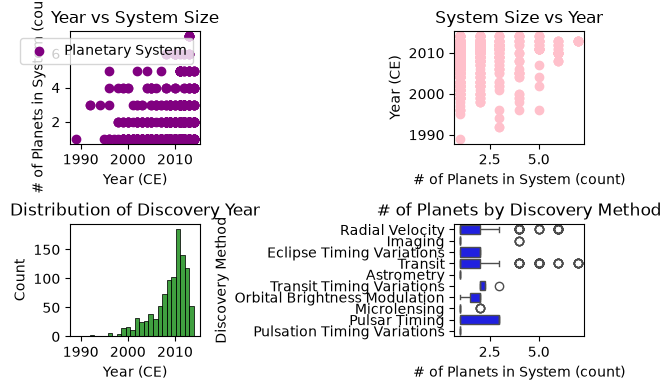

In [49]:
fig, axes = plt.subplots(2,2,figsize=(6,4))

axes[0,0].scatter(df2["year"], df2["number"], color="purple", label="Planetary System")
axes[0,0].set_xlabel("Year (CE)")
axes[0,0].set_ylabel("# of Planets in System (count)")
axes[0,0].set_title("Year vs System Size")
axes[0,0].legend()

axes[0,1].scatter(df2["number"], df2["year"], color="pink")
axes[0,1].set_xlabel("# of Planets in System (count)")
axes[0,1].set_ylabel("Year (CE)")
axes[0,1].set_title("System Size vs Year")

sns.histplot(data=df2, x="year", ax=axes[1,0], color="green")
axes[1,0].set_title("Distribution of Discovery Year")
axes[1,0].set_xlabel("Year (CE)")

sns.boxplot(data=df2, x="number", y="method", ax=axes[1,1], color="blue")
axes[1,1].set_title("# of Planets by Discovery Method")
axes[1,1].set_xlabel("# of Planets in System (count)")
axes[1,1].set_ylabel("Discovery Method")

plt.tight_layout()
plt.show()

'''
Top Left Plot: Shows year of discovery vs number of planets in the system
            I graphed it because I was interested if more complex systems were found more recently
            More complex systems were only found more recently
Top Right Plot: The same quantities swapped because I did not have enough columns with data
            This view makes the years for each system size more clear
            Single planet systems have been found since the beginning of the data until the present day
Bottom Left Plot: Histogram of discovery year
            I was curious when the most planets were discovered 
            Planet discovery peaked soon after 2010, with discoveries decreasing after
Bottom Right Plot: Boxplot of the complexity of system size based on discovery method
            I wondered if the research method influenced if larger systems were discovered
            While most methods produced similar distributions, radial velocity and transit were able to discover many large outlier systems.
'''